<a href="https://colab.research.google.com/github/sohamshelke266-boop/Smart-City-Traffic-Flow-Simulator/blob/main/Smart_City_Traffic_Flow_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imports, seed, and hourly rush-hour curve

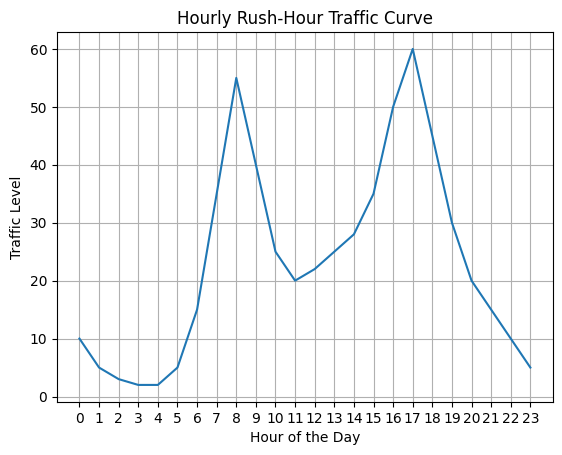

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

hours = np.arange(24)

traffic_curve = np.array([
    10, 5, 3, 2, 2, 5, 15, 35,
    55, 40, 25, 20, 22, 25, 28, 35,
    50, 60, 45, 30, 20, 15, 10, 5
])

plt.plot(hours, traffic_curve)
plt.title("Hourly Rush-Hour Traffic Curve")
plt.xlabel("Hour of the Day")
plt.ylabel("Traffic Level")
plt.xticks(hours)
plt.grid()
plt.show()

Simulate traffic for 30 days and 10 junctions

In [2]:
days = 30
junctions = 10
hours = 24

traffic = np.zeros((days, junctions, hours))

for day in range(days):
    for junction in range(junctions):
        for hour in range(hours):
            traffic[day, junction, hour] = np.random.poisson(
                traffic_curve[hour] + junction * 2
            )

print("Traffic data shape:", traffic.shape)
print("Total vehicles:", np.sum(traffic))
print("Average vehicles per hour:", np.mean(traffic))

Traffic data shape: (30, 10, 24)
Total vehicles: 232858.0
Average vehicles per hour: 32.341388888888886


Aggregate traffic and find peak hours with argmax

In [3]:
hourly_traffic = np.sum(traffic, axis=(0, 1))

peak_hour = np.argmax(hourly_traffic)

junction_traffic = np.sum(traffic, axis=(0, 2))

busiest_junction = np.argmax(junction_traffic)

print("Total traffic by hour:")
print(hourly_traffic)

print("Peak traffic hour:", peak_hour)
print("Peak hour vehicles:", hourly_traffic[peak_hour])

print("Traffic by junction:")
print(junction_traffic)

print("Busiest junction:", busiest_junction + 1)
print("Busiest junction vehicles:", junction_traffic[busiest_junction])

Total traffic by hour:
[ 5649.  4097.  3629.  3366.  3280.  4264.  7126. 13170. 19060. 14557.
 10187.  8788.  9246. 10165. 11225. 13222. 17748. 20607. 16140. 11725.
  8602.  7209.  5608.  4188.]
Peak traffic hour: 17
Peak hour vehicles: 20607.0
Traffic by junction:
[16807. 18216. 19760. 20945. 22470. 24235. 25432. 27065. 28060. 29868.]
Busiest junction: 10
Busiest junction vehicles: 29868.0


Heatmap and loop vs. vectorized execution time

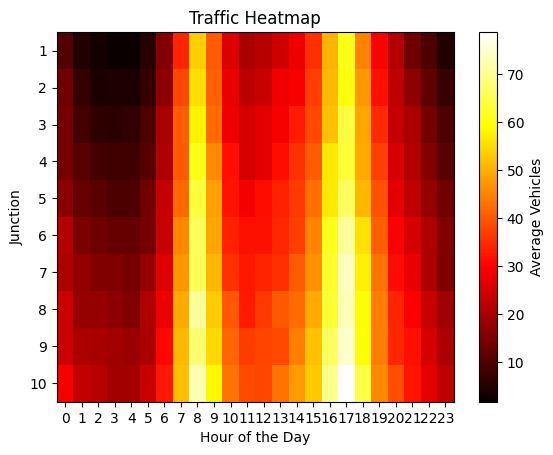

In [4]:
average_traffic = np.mean(traffic, axis=0)

plt.imshow(average_traffic, aspect="auto", cmap="hot")
plt.title("Traffic Heatmap")
plt.xlabel("Hour of the Day")
plt.ylabel("Junction")
plt.xticks(np.arange(24))
plt.yticks(np.arange(10), np.arange(1, 11))
plt.colorbar(label="Average Vehicles")
plt.show()

In [5]:
import time

data = np.random.randint(0, 100, size=(1000, 1000))

start = time.time()

total_loop = 0

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        total_loop += data[i, j]

loop_time = time.time() - start

start = time.time()

total_numpy = np.sum(data)

numpy_time = time.time() - start

print("Loop total:", total_loop)
print("NumPy total:", total_numpy)

print("Loop time:", loop_time)
print("NumPy time:", numpy_time)

if numpy_time > 0:
    print("Speed improvement:", loop_time / numpy_time)

Loop total: 49478830
NumPy total: 49478830
Loop time: 0.3669545650482178
NumPy time: 0.0013790130615234375
Speed improvement: 266.0994121715076
